<div dir="rtl">

# UniFeedback
### نظام لتحليل آراء الطلاب حول خدمات الجامعة

يواجه منسوبو الجامعة من طلاب وموظفين وأعضاء هيئة تدريس مشكلات متعددة في خدماتها، مثل تعطل نظام التسجيل، وتأخر الحافلات، وضعف الشبكة، وأعطال المرافق. وفي كثير من الجامعات لا توجد قناة سهلة وسريعة لإيصال هذه الملاحظات، ولا جهة واضحة تجمعها وتحللها. كما أن الملاحظات تصل بأعداد كبيرة، وبالعربية والإنجليزية، وبالفصحى والعامية، مما يجعل قراءتها يدويًا صعبة ويؤدي إلى ضياع مشكلات مهمة.

يعالج UniFeedback هذه المشكلة بتحليل الملاحظات آليًا باستخدام نماذج المحوّلات (Transformers):

| المرحلة | الوصف | المصدر |
|---|---|---|
| 1 | تنظيف النص وإخفاء البيانات الشخصية | Lab 1 |
| 2 | فهم الكلمة من سياقها عبر آلية الانتباه | Lab 2 |
| 3 | تصنيف الرأي حسب موضوعه: تسجيل، مواصلات، شبكة، مرافق | Lab 3A |
| 4 | معالجة خصائص العربية: الزوائد، وتوحيد الحروف، واللهجات | Lab 3B، Lab 4 |
| 5 | البحث الدلالي عن الآراء المتشابهة بين لغتين | Lab 5 |
| 6 | التقييم المقسّم وتحليل الأخطاء | Lab 6 |
| 7 | عرض تطبيقي (Demo) | — |

**التشغيل:** Runtime ← Change runtime type ← T4 GPU، ثم Runtime ← Run all.

</div>

<div dir="rtl">

## 0. التجهيز
تثبيت المكتبات المطلوبة واستيرادها مرة واحدة للمشروع كاملًا.

</div>

In [1]:
# 🧪 Setup: Installation & Imports
!pip install -q transformers datasets scikit-learn pandas matplotlib sentence-transformers faiss-cpu

import pandas as pd
import re
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

pd.set_option("display.max_colwidth", None)   # Show full text in all tables
project_name = "UniFeedback"
print("✅ Setup Ready —", project_name)

✅ Setup Ready — UniFeedback


<div dir="rtl">

## 1. تنظيف النص وحماية الخصوصية (Lab 1)
- **البيانات:** ثمانية آراء (أربعة بالعربية وأربعة بالإنجليزية) تحتوي على مسافات زائدة وحروف مكررة مثل "يوووم"، لمحاكاة الكتابة الفعلية.
- **التنظيف (Normalisation):** إزالة المسافات الزائدة والحروف المكررة.
- **إخفاء البيانات الشخصية (PII Masking):** استبدال أرقام الجوال بـ `[PHONE]` والبريد الإلكتروني بـ `[EMAIL]`، حمايةً للخصوصية وتطبيقًا لنظام حماية البيانات الشخصية (PDPL).

</div>

In [2]:
# 🧪 Lab 1 — Code 3: Create Dataset

# 🏷️ Project Name
project_name = "UniFeedback"

# 📝 Project Dataset
data = {
    "language": ["ar", "ar", "ar", "ar", "en", "en", "en", "en"],
    "text": [
        "  نظام   التسجيل   يعلق   وقت   تسجيل المواد  ",
        "المكتبة    هادئة   والموظفين   متعاونين",
        "  الباص   يتأخر   كل يوووم   عن المحاضرة الأولى  ",
        "  أكل   الكافتيريا   غالي   ومو صحي  ",
        "  The   student portal    is very slow  ",
        "Library    staff were   really helpful",
        "  I cannot   register for    my courses  ",
        "  The   campus Wi-Fi    keeps disconnecting  "
    ]
}

# 📊 Create DataFrame
df = pd.DataFrame(data)

# ✅ Confirmation
print("🧪 Project:", project_name)
print("✅ Dataset created successfully!")

# 📊 Display Dataset
display(df)

🧪 Project: UniFeedback
✅ Dataset created successfully!


,language,text
0,ar,نظام التسجيل يعلق وقت تسجيل المواد
1,ar,المكتبة هادئة والموظفين متعاونين
2,ar,الباص يتأخر كل يوووم عن المحاضرة الأولى
3,ar,أكل الكافتيريا غالي ومو صحي
4,en,The student portal is very slow
5,en,Library staff were really helpful
6,en,I cannot register for my courses
7,en,The campus Wi-Fi keeps disconnecting


In [3]:
# 🧪 Lab 1 — Code 4: Text Normalisation
import re
from IPython.display import HTML, display

def normalize(text):
    text = re.sub(r"(.)\1{2,}", r"\1", str(text))   # Remove repeated letters
    return re.sub(r"\s+", " ", text).strip()        # Remove extra spaces

df["clean_text"] = df["text"].apply(normalize)

print("✅ Normalisation Completed!")
display(HTML(df[["text", "clean_text"]].to_html(index=False)))

✅ Normalisation Completed!


text,clean_text
نظام التسجيل يعلق وقت تسجيل المواد,نظام التسجيل يعلق وقت تسجيل المواد
المكتبة هادئة والموظفين متعاونين,المكتبة هادئة والموظفين متعاونين
الباص يتأخر كل يوووم عن المحاضرة الأولى,الباص يتأخر كل يوم عن المحاضرة الأولى
أكل الكافتيريا غالي ومو صحي,أكل الكافتيريا غالي ومو صحي
The student portal is very slow,The student portal is very slow
Library staff were really helpful,Library staff were really helpful
I cannot register for my courses,I cannot register for my courses
The campus Wi-Fi keeps disconnecting,The campus Wi-Fi keeps disconnecting


In [4]:
# 🧪 Lab 1 — Code 5: PII Masking

# 📝 Add Sample Personal Information
df.loc[0, "clean_text"] = (
    "نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على "
    "0551234567 أو student@uni.edu.sa"
)

df.loc[2, "clean_text"] = (
    "الباص يتأخر كل يوم عن المحاضرة الأولى "
    "راسلوني على sara.ahmed@gmail.com أو 0509876543"
)

df.loc[4, "clean_text"] = (
    "The student portal is very slow "
    "please contact me at 0567891234"
)

df.loc[6, "clean_text"] = (
    "I cannot register for my courses "
    "email me at reem.ali@outlook.com or call 0531112233"
)

# 🛡️ Define Masking Function
def mask_pii(text):
    text = str(text)

    # Mask Email Addresses
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b', '[EMAIL]', text)

    # Mask Saudi Mobile Numbers
    text = re.sub(r'\b05\d{8}\b', '[PHONE]', text)

    return text

# 🔒 Apply Masking
df["masked_text"] = df["clean_text"].apply(mask_pii)

# 📊 Display Results
display(df[["clean_text", "masked_text"]])

,clean_text,masked_text
0,نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على 0551234567 أو student@uni.edu.sa,نظام التسجيل يعلق وقت تسجيل المواد تواصلوا معي على [PHONE] أو [EMAIL]
1,المكتبة هادئة والموظفين متعاونين,المكتبة هادئة والموظفين متعاونين
2,الباص يتأخر كل يوم عن المحاضرة الأولى راسلوني على sara.ahmed@gmail.com أو 0509876543,الباص يتأخر كل يوم عن المحاضرة الأولى راسلوني على [EMAIL] أو [PHONE]
3,أكل الكافتيريا غالي ومو صحي,أكل الكافتيريا غالي ومو صحي
4,The student portal is very slow please contact me at 0567891234,The student portal is very slow please contact me at [PHONE]
5,Library staff were really helpful,Library staff were really helpful
6,I cannot register for my courses email me at reem.ali@outlook.com or call 0531112233,I cannot register for my courses email me at [EMAIL] or call [PHONE]
7,The campus Wi-Fi keeps disconnecting,The campus Wi-Fi keeps disconnecting


<div dir="rtl">

## 2. آلية فهم النموذج للجملة (Lab 2)
- **خريطة الانتباه (Attention Map):** تشغيل نموذج CAMeLBERT على جملة من بيانات المشروع، وعرض قوة الارتباط بين كلماتها؛ فكلما كان اللون أغمق كان الانتباه أقوى.
- **تسرب الحشو (PAD Leak):** إكمال الجملة بوحدات فارغة `[PAD]` ومقارنة الانتباه إليها مع قناع الانتباه وبدونه. مع القناع يكون الانتباه للحشو صفرًا، وبدونه يمنح النموذج الحشو جزءًا كبيرًا من انتباهه، وهو خطأ صامت لا يظهر له تنبيه.

</div>

config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


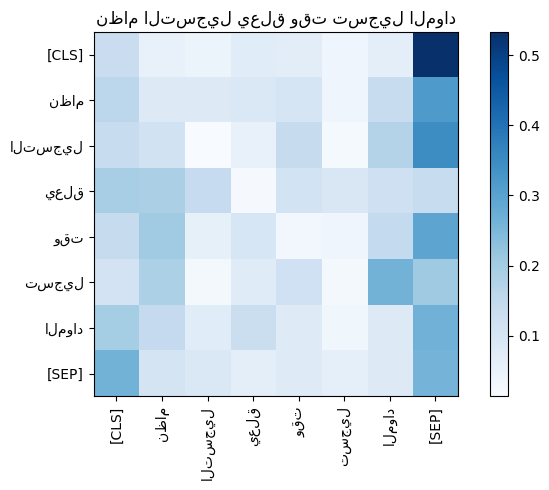

✅ Attention Map Completed!


In [5]:
# 🧪 Lab 2 — Code 6: Attention Maps


from transformers import AutoTokenizer, AutoModel


# 🤖 Load Model

name = "CAMeL-Lab/bert-base-arabic-camelbert-mix"

tok = AutoTokenizer.from_pretrained(name)

model = AutoModel.from_pretrained(

    name, attn_implementation="eager"

).eval()


# ✏️ Change the text here

texts = [
    "نظام التسجيل يعلق وقت تسجيل المواد",
    "المكتبة هادئة والموظفين متعاونين",
    "الباص يتأخر عن المحاضرة الأولى",
    "الواي فاي في الجامعة ضعيف",
    "إضاءة القاعات خافته",
    "المصعد مو شغال كل الوقت"
]
text = texts[0]


# 🧠 Calculate Attention

inputs = tok(text, return_tensors="pt")


with torch.no_grad():

    att = model(**inputs, output_attentions=True).attentions


# 📊 Display Attention Map

tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])


plt.figure(figsize=(7, 5))

plt.imshow(att[0][0, 0].numpy(), cmap="Blues")

plt.xticks(range(len(tokens)), tokens, rotation=90)

plt.yticks(range(len(tokens)), tokens)

plt.title(text)

plt.colorbar()

plt.tight_layout()

plt.show()


print("✅ Attention Map Completed!")

In [6]:
# 🧪 Lab 2 — Code 7: PAD Leak Detection


# ✏️ Change padding length here

pad_length = 36


# 🔤 Use Text from Code 6

size = max(pad_length, len(tok.encode(text)) + 4)

inputs = tok(text, return_tensors="pt",

             padding="max_length", max_length=size)


# 🧠 Compare With / Without Mask

with torch.no_grad():

    with_mask = model(**inputs, output_attentions=True).attentions[0][0, 0]

    without_mask = model(

        input_ids=inputs["input_ids"], output_attentions=True

    ).attentions[0][0, 0]


# 📊 Display Results

pads = inputs["attention_mask"][0] == 0

valid = ~pads


print("✅ PAD Leak Test Completed!")

print("PAD Count:", pads.sum().item())

print("With Mask:", round(with_mask[valid][:, pads].sum(-1).mean().item(), 4))

print("Without Mask:", round(without_mask[valid][:, pads].sum(-1).mean().item(), 4))

✅ PAD Leak Test Completed!
PAD Count: 28
With Mask: 0.0
Without Mask: 0.5649


<div dir="rtl">

## 3. تصنيف الآراء (Lab 3A)
- **البيانات:** أربعون رأيًا من عشرين طالبًا، بواقع عشرة آراء لكل موضوع، وتشمل جملًا عامية من Lab 4.
- **التقسيم حسب الطالب (GroupShuffleSplit):** توضع آراء الطالب الواحد كلها في القسم نفسه لمنع تسرب البيانات (Data Leakage)، إذ قد يكتب الطالب رأيين متقاربين جدًا.
- **النموذج:** CAMeLBERT، وهو نموذج Encoder عربي، مع رأس تصنيف جديد بعدد المواضيع.
- **إعدادات التدريب:** `epochs=10`، `batch_size=4`، `learning_rate=5e-5`.
- **النتيجة:** بلغت قيمة `eval_loss` نحو 1.30 عند التدريب على 16 رأيًا، وهي قريبة من التخمين العشوائي، ثم انخفضت إلى 0.23 بعد زيادة البيانات إلى 40 رأيًا.

</div>

In [7]:
# 🧪 Lab 3A — Code 2: Custom Dataset Preparation
import pandas as pd

# بيانات المشروع - يمكن تعديلها
data = {
    "student_id": [1, 1, 2, 2, 3, 3, 4, 4, 5, 5,
                   6, 6, 7, 7, 8, 8, 9, 9, 10, 10,
                   11, 11, 12, 12, 13, 13, 14, 14, 15, 15,
                   16, 16, 17, 17, 18, 18, 19, 19, 20, 20],
    "text": [
        # registration
        "نظام التسجيل يعلق وقت تسجيل المواد",
        "البانر من أمس معلق",
        "ما قدرت أسجل المواد من البوابة",
        "أبغى أسجل في شعبة الصباح",
        "الشعب تقفل بسرعة وقت التسجيل",
        "ليه أغلب الشعب مقفلة",
        "ما فيه مقاعد كافية في المواد الإجبارية",
        "أبي أنزل مادة زيادة",
        "أبي أغير شعبتي",
        "أبي أحذف المادة",
        # transport
        "الباص يتأخر عن المحاضرة الأولى",
        "مواعيد الباصات غير منتظمة",
        "الباص زحمة ومافيه مكان",
        "زيدوا عدد الباصات الترددية",
        "محطة الباص بعيدة عن المباني",
        "ما فيه باص يوصل للسكن بالليل",
        "السواق مشى قبل لا أركب",
        "ننتظر الباص أكثر من نص ساعة",
        "مواقف السيارات دايم زحمة",
        "الباص الترددي يتأخر بين المباني",
        # wifi
        "الواي فاي في الجامعة ضعيف",
        "ما أقدر أتصل بشبكة الجامعة",
        "الإنترنت يفصل كل شوي في القاعات",
        "الانترنت يفصل كل شوي داخل القاعات",
        "الواي فاي بطيء في السكن",
        "التغطية ضعيفة في مبنى الكلية",
        "كلمة مرور الواي فاي ما تشتغل",
        "النت ثقيل مرة في المعامل",
        "ما أقدر أحمل المحاضرات من بطء الشبكة",
        "الواي فاي ينقطع وقت الاختبارات الإلكترونية",
        # facilities
        "دورات المياه مغلقه",
        "دورات المياه مافيها مويه",
        "إضاءة القاعات خافته",
        "اللمبات خافته",
        "المصعد مو شغال كل الوقت",
        "المصاعد خربانه",
        "آلات الطعام معطله",
        "الات الطعام خربانه",
        "المكيف خربان في القاعة",
        "الكراسي مكسورة في المدرج"
    ],
    "topic": ["registration"] * 10 + ["transport"] * 10 + ["wifi"] * 10 + ["facilities"] * 10
}

df = pd.DataFrame(data)

topics = sorted(df["topic"].unique())
label_map = {topic: i for i, topic in enumerate(topics)}
df["label"] = df["topic"].map(label_map)

print(df)
print("\nLabels:", label_map)
print("Total:", len(df), "| Per topic:", df["topic"].value_counts().to_dict())

    student_id                                        text         topic  \
0            1          نظام التسجيل يعلق وقت تسجيل المواد  registration   
1            1                          البانر من أمس معلق  registration   
2            2              ما قدرت أسجل المواد من البوابة  registration   
3            2                    أبغى أسجل في شعبة الصباح  registration   
4            3                الشعب تقفل بسرعة وقت التسجيل  registration   
5            3                        ليه أغلب الشعب مقفلة  registration   
6            4      ما فيه مقاعد كافية في المواد الإجبارية  registration   
7            4                         أبي أنزل مادة زيادة  registration   
8            5                              أبي أغير شعبتي  registration   
9            5                             أبي أحذف المادة  registration   
10           6              الباص يتأخر عن المحاضرة الأولى     transport   
11           6                   مواعيد الباصات غير منتظمة     transport   
12          

In [8]:
# 🧪 Lab 3A — Code 3: GroupShuffleSplit

from sklearn.model_selection import GroupShuffleSplit


# ✏️ يمكن تعديل القيم حسب

test_size = 0.20

random_state = 7

group_column = "student_id"


gss = GroupShuffleSplit(

    n_splits=1,

    test_size=test_size,

    random_state=random_state

)


train_idx, test_idx = next(

    gss.split(df, groups=df[group_column])

)


train_df = df.iloc[train_idx]

test_df = df.iloc[test_idx]


shared = set(train_df[group_column]) & set(test_df[group_column])


print("Train:", len(train_df))

print("Test:", len(test_df))

print("Shared Students:", shared)

Train: 32
Test: 8
Shared Students: set()


In [9]:
# 🧪 Lab 3A — Code 4: Tokenization & Dataset Preparation
from transformers import AutoTokenizer
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-mix")

sample_texts = ["نظام التسجيل يعلق وقت تسجيل المواد",
                "ماقدرت اسجل المواد من البوابه"]


def prepare_data(data):
    tokens = tokenizer(data["text"].tolist(), padding=True, truncation=True)
    tokens["labels"] = data["label"].tolist()
    return Dataset.from_dict(tokens)


train_dataset = prepare_data(train_df)
test_dataset = prepare_data(test_df)


for sample in sample_texts:
    print("Text:", sample)
    print("Tokens:", tokenizer.tokenize(sample))
    print("Input IDs:", tokenizer.encode(sample))
    print()

print("✅ Dataset Ready!")
print("Train:", len(train_dataset), "| Test:", len(test_dataset))

Text: نظام التسجيل يعلق وقت تسجيل المواد
Tokens: ['نظام', 'التسجيل', 'يعلق', 'وقت', 'تسجيل', 'المواد']
Input IDs: [2, 3701, 4441, 22713, 2758, 6131, 4989, 3]

Text: ماقدرت اسجل المواد من البوابه
Tokens: ['ماقد', '##رت', 'اس', '##جل', 'المواد', 'من', 'البوا', '##به']
Input IDs: [2, 23565, 2148, 2171, 2293, 4989, 1908, 7712, 2204, 3]

✅ Dataset Ready!
Train: 32 | Test: 8


In [10]:
# 🧪 Lab 3A — Code 5: Load Model

from transformers import AutoModelForSequenceClassification


num_labels = len(topics)


model = AutoModelForSequenceClassification.from_pretrained(

    "CAMeL-Lab/bert-base-arabic-camelbert-mix",

    num_labels=num_labels

)


print("✅ Model Ready!")

print("Number of Labels:", num_labels)

print("Topics:", topics)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

✅ Model Ready!
Number of Labels: 4
Topics: ['facilities', 'registration', 'transport', 'wifi']


In [11]:
# 🧪 Lab 3A — Code 6: Model Training & Evaluation

from transformers import TrainingArguments, Trainer


epochs = 10

batch_size = 4

learning_rate = 5e-5


args = TrainingArguments(

    output_dir="./results",

    num_train_epochs=epochs,

    per_device_train_batch_size=batch_size,

    learning_rate=learning_rate,

    report_to="none"

)


trainer = Trainer(

    model=model,

    args=args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset

)


trainer.train()

print("✅ Training Complete!")

print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Training Complete!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,0.230722,80


{'eval_loss': 0.23072202503681183}


<div dir="rtl">

## 4. خصائص اللغة العربية (Lab 3B، Lab 4)
- **الزوائد (Clitics):** كلمات مثل "والمكتبة" و"بالقاعة" تنقسم إلى عدة وحدات لاتصال الحروف بالكلمة.
- **توحيد الحروف:** تحويل (أ، إ، آ) إلى (ا)، و(ى) إلى (ي)، و(ة) إلى (ه)، لتُعامل "مغلقة" و"مغلقه" كلمةً واحدة.
- **تدقيق اللهجات (Dialect Audit):** عرض المعنى نفسه بالفصحى والعامية؛ إذ تفقد النماذج المدربة على الفصحى جزءًا من دقتها مع العامية دون أن يظهر ذلك، لذا يلزم معرفة طبيعة البيانات قبل اختيار النموذج.

</div>

In [12]:
# 🧪 Lab 3B — Code 3: Arabic Clitic-Splitting

words = ["والمكتبة", "بالقاعة", "وللمصعد"]


tokens = tokenizer(words, is_split_into_words=True)


token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])


for token, word_id in zip(token_list, tokens.word_ids()):

    print(token, "→", word_id)

[CLS] → None
والمك → 0
##تبة → 0
بالق → 1
##اعة → 1
وللم → 2
##ص → 2
##عد → 2
[SEP] → None


In [13]:
# 🧪 Lab 4 — Code 1: Arabic Normalization

import re

def normalize_arabic(text):
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    return text

texts = ["لا يوجد مقاعد كافية في المواد الإجبارية",
         "أريد التسجيل في شعبة الصباح"]

for text in texts:
    print("Before:", text)
    print("After :", normalize_arabic(text))
    print()

Before: لا يوجد مقاعد كافية في المواد الإجبارية
After : لا يوجد مقاعد كافيه في المواد الاجباريه

Before: أريد التسجيل في شعبة الصباح
After : اريد التسجيل في شعبه الصباح



In [14]:
# 🧪 Lab 4 — Code 2: Dialect Audit

texts = [

    "أريد التسجيل في شعبة الصباح",

    "ابغى اسجل في الشعبة الصباحية",

    "بسجل بالشعبه حقت الصباح"

]


for text in texts:

    print(text)

أريد التسجيل في شعبة الصباح
ابغى اسجل في الشعبة الصباحية
بسجل بالشعبه حقت الصباح


<div dir="rtl">

## 5. البحث الدلالي ثنائي اللغة (Lab 5)
- **الفكرة:** البحث بالمعنى لا بالكلمات؛ فالنموذج متعدد اللغات يضع الجمل المتقاربة في المعنى متجاورةً حتى لو كانت بلغتين مختلفتين.
- **النتيجة:** أعاد البحث بالجملة الإنجليزية *"The bus is always late"* الرأيَ العربي "الباص يتأخر عن المحاضرة الأولى" في المرتبة الأولى دون ترجمة.

</div>

In [15]:
# 🧪 Lab 5 — Code 1: Build FAISS Index

from sentence_transformers import SentenceTransformer

import faiss


texts = [
    "الباص يتأخر عن المحاضرة الأولى",
    "الواي فاي في الجامعة ضعيف",
    "نظام التسجيل يعلق وقت تسجيل المواد",
    "المصعد مو شغال كل الوقت",
    "The library closes too early"
]

search_model = SentenceTransformer(

    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

)


embeddings = search_model.encode(texts)


index = faiss.IndexFlatL2(embeddings.shape[1])


index.add(embeddings)


print("عدد النصوص في FAISS:", index.ntotal)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

عدد النصوص في FAISS: 5


In [16]:
# 🧪 Lab 5 — Code 2: Semantic Search

query = "The bus is always late"


query_embedding = search_model.encode([query])


distances, indices = index.search(query_embedding, 3)


print("Query:", query)

print("Results:")


for i in indices[0]:

    print("-", texts[i])

Query: The bus is always late
Results:
- الباص يتأخر عن المحاضرة الأولى
- نظام التسجيل يعلق وقت تسجيل المواد
- المصعد مو شغال كل الوقت


<div dir="rtl">

## 6. التقييم وتحليل الأخطاء (Lab 6)
- **التقييم المقسّم (Sliced Evaluation):** تقسيم النتائج حسب اللغة واللهجة والطول، لأن الرقم الإجمالي قد يخفي ضعف النموذج مع العامية.
- **تحليل الأخطاء:** تصنيف الأخطاء حسب أسبابها، مثل تشابه موضوعين ("البوابة")، أو سؤال خارج النطاق ("وش أفضل مطعم؟")، ولكل نوع معالجة مختلفة.

*الأمثلة في هذا القسم توضيحية لطريقة التقييم.*

</div>

In [17]:
# 🧪 Lab 6 — Code 1: Sliced Evaluation

students = [
    {"language": "Arabic", "dialect": "Saudi", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "Saudi", "length": "Long", "correct": 0},
    {"language": "Arabic", "dialect": "MSA", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "MSA", "length": "Long", "correct": 1},
    {"language": "Arabic", "dialect": "Egyptian", "length": "Short", "correct": 0},
    {"language": "English", "dialect": "Standard", "length": "Short", "correct": 1},
    {"language": "English", "dialect": "Standard", "length": "Long", "correct": 1}
]


for student in students:

    print(

        student["language"],

        "|", student["dialect"],

        "|", student["length"],

        "| Correct:", student["correct"]

    )

Arabic | Saudi | Short | Correct: 1
Arabic | Saudi | Long | Correct: 0
Arabic | MSA | Short | Correct: 1
Arabic | MSA | Long | Correct: 1
Arabic | Egyptian | Short | Correct: 0
English | Standard | Short | Correct: 1
English | Standard | Long | Correct: 1


In [18]:
# 🧪 Lab 6 — Code 3: Error Analysis

errors = [
    ("النت خربان في المكتبة", "واي فاي", "واي فاي"),
    ("الباص ما جا اليوم", "مواصلات", "مواصلات"),
    ("ما قدرت أفتح البوابة", "تسجيل", "واي فاي"),
    ("وش أفضل مطعم قريب من الجامعة؟", "خارج النطاق", "مرافق")
]

for text, actual, predicted in errors:

    print("البلاغ:", text)

    print("التصنيف الصحيح:", actual)

    print("توقع النموذج:", predicted)

    print("التقييم:", "صحيح" if actual == predicted else "خطأ")

    print("-" * 30)

البلاغ: النت خربان في المكتبة
التصنيف الصحيح: واي فاي
توقع النموذج: واي فاي
التقييم: صحيح
------------------------------
البلاغ: الباص ما جا اليوم
التصنيف الصحيح: مواصلات
توقع النموذج: مواصلات
التقييم: صحيح
------------------------------
البلاغ: ما قدرت أفتح البوابة
التصنيف الصحيح: تسجيل
توقع النموذج: واي فاي
التقييم: خطأ
------------------------------
البلاغ: وش أفضل مطعم قريب من الجامعة؟
التصنيف الصحيح: خارج النطاق
توقع النموذج: مرافق
التقييم: خطأ
------------------------------


<div dir="rtl">

## 7. العرض التطبيقي (Demo)
1. إدخال آراء جديدة لم يرها النموذج أثناء التدريب.
2. تصنيف كل رأي حسب موضوعه.
3. رسم بياني يوضح عدد الآراء في كل موضوع، لتحديد أكثر المشكلات تكرارًا.
4. البحث عن آراء مشابهة في البيانات، بما في ذلك البحث بالإنجليزية.

يمكن تعديل الآراء أو جملة البحث في الخلية التالية وإعادة تشغيلها.

</div>

🏷️ Predicted Topics:


,feedback,predicted_topic
0,الباص ما جا اليوم,transport
1,الباصات زحمة الصبح,transport
2,السواق ما وقف عند المحطة,transport
3,النت مقطوع في السكن,wifi
4,الواي فاي ما يشتغل في القاعة,wifi
5,ما قدرت أسجل المادة,registration
6,المكيف ما يبرد في المعمل,facilities


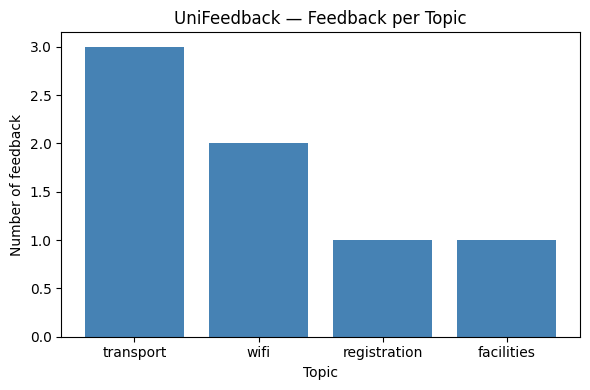

🔎 Query: The bus is always late
Similar feedback:
- الباص الترددي يتأخر بين المباني
- مواعيد الباصات غير منتظمة
- الباص زحمة ومافيه مكان

✅ Demo Completed!


In [19]:
# 🎬 Demo — UniFeedback in Action
import faiss

model.eval()
id2label = {i: t for t, i in label_map.items()}

# ✏️ Change the feedback here
new_feedback = [
    "الباص ما جا اليوم",
    "الباصات زحمة الصبح",
    "السواق ما وقف عند المحطة",
    "النت مقطوع في السكن",
    "الواي فاي ما يشتغل في القاعة",
    "ما قدرت أسجل المادة",
    "المكيف ما يبرد في المعمل"
]


# 1) Classify each feedback
def predict_topic(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True).to(model.device)
    with torch.no_grad():
        pred = model(**inputs).logits.argmax(-1).item()
    return id2label[pred]

results_df = pd.DataFrame({
    "feedback": new_feedback,
    "predicted_topic": [predict_topic(t) for t in new_feedback]
})
print("🏷️ Predicted Topics:")
display(results_df)


# 2) Chart: which topic has the most feedback?
counts = results_df["predicted_topic"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color="steelblue")
plt.title("UniFeedback — Feedback per Topic")
plt.xlabel("Topic")
plt.ylabel("Number of feedback")
plt.tight_layout()
plt.show()


# 3) Find similar feedback (bilingual semantic search)
# ✏️ Change the search query here
query = "The bus is always late"

all_feedback = df["text"].tolist()
feedback_embeddings = search_model.encode(all_feedback)
demo_index = faiss.IndexFlatL2(feedback_embeddings.shape[1])
demo_index.add(feedback_embeddings)

_, idx = demo_index.search(search_model.encode([query]), 3)

print("🔎 Query:", query)
print("Similar feedback:")
for i in idx[0]:
    print("-", all_feedback[i])

print("\n✅ Demo Completed!")

<div dir="rtl">

## الخلاصة
- **الخصوصية أولًا:** تُخفى البيانات الشخصية قبل أي معالجة.
- **أثر حجم البيانات:** زيادة البيانات من 16 إلى 40 رأيًا خفّضت `eval_loss` من 1.30 إلى 0.23.
- **خصوصية اللغة العربية:** تتطلب الزوائد وأشكال الحروف واللهجات معالجة خاصة.
- **البحث بالمعنى يتجاوز حاجز اللغة:** بحث بالإنجليزية يعيد آراء مكتوبة بالعربية.
- **التقييم الدقيق:** تقسيم النتائج وتحليل الأخطاء بدل الاكتفاء برقم واحد.

**حدود المشروع:** البيانات تجريبية وصغيرة، والمصنّف مدرّب على العربية.
**التطويرات المستقبلية:** جمع بيانات حقيقية أكثر، واستخراج الكيانات (الخدمة والمكان)، وتحليل المشاعر، وتوسيع النظام ليشمل الموظفين وأعضاء هيئة التدريس.

</div>